# 02 - Preprocessing

Goal: explain each preparation step, and show why oversampling must come after the split.

Reproduces: paper Sections 4.1 and 4.1.2.

Needs: nothing. The functions used here are in utils.py (load_data, make_inputs, split_data, get_metrics, set_style).

Expected run time: under 1 minute.

Status: executed

## 1. Setup
One split is enough to show the steps, so N_REPEATS is not used in this notebook. We use seed 42.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Windows: set before the other imports

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from utils import COLOURS, NUM_COLS, SEED, get_metrics, load_data, make_inputs, set_style, split_data

N_REPEATS = 10  # paper uses 100 (not used here: one demonstration split)
set_style()

## 2. One-hot coding
One-hot coding (the paper calls it 1-of-C coding) turns each category into its own column of 0s and 1s. We do this because category numbers have no real order. Region 3 is not "more" than Region 2. Weekend is already 0 or 1. The paper reports 70 input neurons.

In [2]:
df = load_data()
X, y = make_inputs(df)
print("Input columns:", X.shape[1], "(paper: 70)")
print("  numerical:", len(NUM_COLS), "| Weekend: 1 | one-hot:", X.shape[1] - len(NUM_COLS) - 1)

Input columns: 74 (paper: 70)
  numerical: 10 | Weekend: 1 | one-hot: 63


We get 74 input columns: 10 numerical, 1 for Weekend and 63 from one-hot coding. That is 4 more than the paper's 70. We could not reproduce the 70. In fact, the category counts in the paper's own Table 2 would give 76, because they include 12 months.

## 3. Split 70/30 and standardize
We use 70% of the sessions to train and 30% to test. The split is stratified, which means both parts keep the same share of buyers. Standardizing rescales each numerical feature to mean 0 and standard deviation 1. We learn the scaling from the train part only and then apply it to both parts.

Deviation from the paper: the paper standardizes before splitting. Our way is stricter, because the test data cannot influence the scaling.

In the table, the train columns should show exactly 0 and 1. The test columns should be close to those values, but not exact.

In [3]:
X_train, X_test, y_train, y_test = split_data(X, y, seed=SEED)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Purchase rate - train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

check = pd.DataFrame({
    "Train mean": X_train[NUM_COLS].mean(), "Train SD": X_train[NUM_COLS].std(),
    "Test mean": X_test[NUM_COLS].mean(), "Test SD": X_test[NUM_COLS].std(),
})
check.round(3)

Train rows: 8631 | Test rows: 3699
Purchase rate - train: 0.1548 | test: 0.1546


,Train mean,Train SD,Test mean,Test SD
Administrative,0.0,1.0,-0.000,1.007
Administrative_Duration,0.0,1.0,-0.005,0.946
Informational,-0.0,1.0,0.000,0.987
Informational_Duration,-0.0,1.0,-0.003,0.963
ProductRelated,0.0,1.0,0.038,1.096
ProductRelated_Duration,0.0,1.0,0.030,1.016
BounceRates,0.0,1.0,0.010,1.000
ExitRates,0.0,1.0,0.002,0.998
PageValues,0.0,1.0,-0.013,0.989
SpecialDay,0.0,1.0,-0.023,0.964


We get 8,631 train rows and 3,699 test rows, with a purchase rate of about 15.5% in both. The train means are 0 and the train standard deviations are 1, as they should be. The test values are close, for example a mean of 0.038 and a standard deviation of 1.096 for ProductRelated.

## 4. Oversample the train part only
Oversampling means copying rows of the smaller class until the two classes have the same size. Here we copy purchase rows in the train part. We never touch the test set, so it keeps its natural mix of buyers.

In [4]:
X_over, X_test_over, y_over, y_test_over = split_data(X, y, seed=SEED, oversample=True)

# The test set must be exactly the same with and without oversampling.
print("Test set unchanged:", X_test.equals(X_test_over) and y_test.equals(y_test_over))
counts = pd.DataFrame({
    "Train before": y_train.value_counts(), "Train after": y_over.value_counts(),
    "Test": y_test.value_counts(),
}).sort_index()
counts.index = ["No purchase", "Purchase"]
print(counts)

Test set unchanged: True
             Train before  Train after  Test
No purchase          7295         7295  3127
Purchase             1336         7295   572


## 5. Class counts before and after
This chart shows the same counts as the table above. Compare the purchase bars.

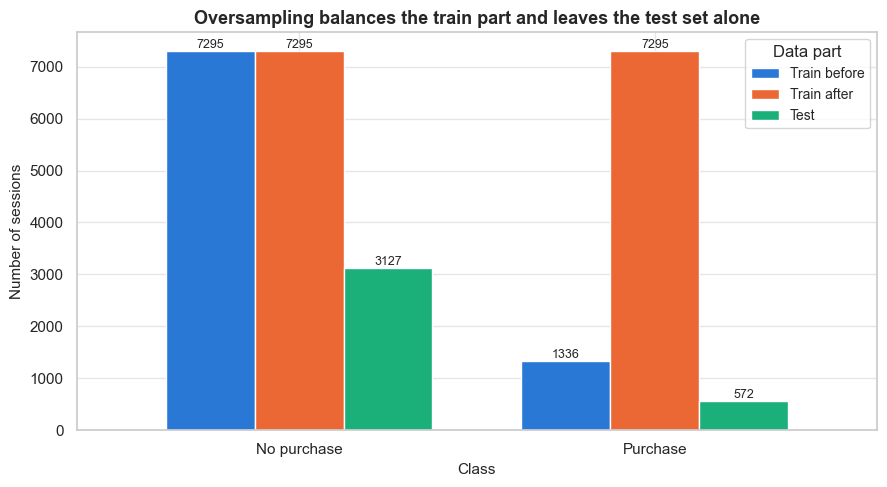

In [5]:
ax = counts.plot(kind="bar", color=COLOURS[:3], width=0.75, rot=0)
for container in ax.containers:
    ax.bar_label(container, fontsize=9)
ax.set_title("Oversampling balances the train part and leaves the test set alone")
ax.set_xlabel("Class")
ax.set_ylabel("Number of sessions")
ax.legend(title="Data part")
plt.tight_layout()
plt.show()

Purchase rows in the train part go from 1,336 to 7,295, which now equals the 7,295 non-purchase rows. The test set stays at 3,127 and 572, and our check confirms it is unchanged.

## 6. Why oversampling must come after the split
Here we do it the wrong way on purpose: we oversample all the data first, and then split. A purchase row and its copy can then land on opposite sides, so the model is tested on rows it has already seen. This is called data leakage. We count those rows, and we compare an unpruned decision tree under both orders.

TPR (true positive rate) is the share of real buyers the model finds. F1 is one score that combines how many buyers the model finds with how many of its "buyer" guesses are right. It is high only when both are good.

In [6]:
# Wrong order: oversample first. sample_indices_ tells us which original row each row came from.
sampler = RandomOverSampler(random_state=SEED)
X_all, y_all = sampler.fit_resample(X, y)
origin = sampler.sample_indices_
pos = np.arange(len(y_all))
train_pos, test_pos = train_test_split(pos, test_size=0.3, stratify=y_all, random_state=SEED)

train_origin = set(origin[train_pos])
test_buyers = test_pos[y_all.values[test_pos] == 1]
leaked = sum(origin[i] in train_origin for i in test_buyers)
print(f"Wrong order: {leaked:,} of {len(test_buyers):,} test purchase rows "
      f"({leaked / len(test_buyers):.1%}) also appear in train")
print("Right order: 0 test rows also appear in train through oversampling")

# Effect on one model: an unpruned tree can memorise the copied rows.
tree = DecisionTreeClassifier(random_state=SEED)
tree.fit(X_all.values[train_pos], y_all.values[train_pos])
wrong = get_metrics(y_all.values[test_pos], tree.predict(X_all.values[test_pos]))
tree = DecisionTreeClassifier(random_state=SEED).fit(X_over, y_over)
right = get_metrics(y_test, tree.predict(X_test))
demo = pd.DataFrame({"Wrong order (leak)": wrong, "Right order": right}).round(3)
print(demo)

Wrong order: 3,041 of 3,127 test purchase rows (97.2%) also appear in train
Right order: 0 test rows also appear in train through oversampling


          Wrong order (leak)  Right order
accuracy               0.944        0.858
tpr                    0.992        0.531
tnr                    0.896        0.918
f1                     0.947        0.537


The leak is large. With the wrong order, 3,041 of 3,127 test purchase rows (97.2%) also appear in train. With the right order, none do.

The chart compares TPR and F1 for the two orders. Look at how far the wrong order is above the right one.

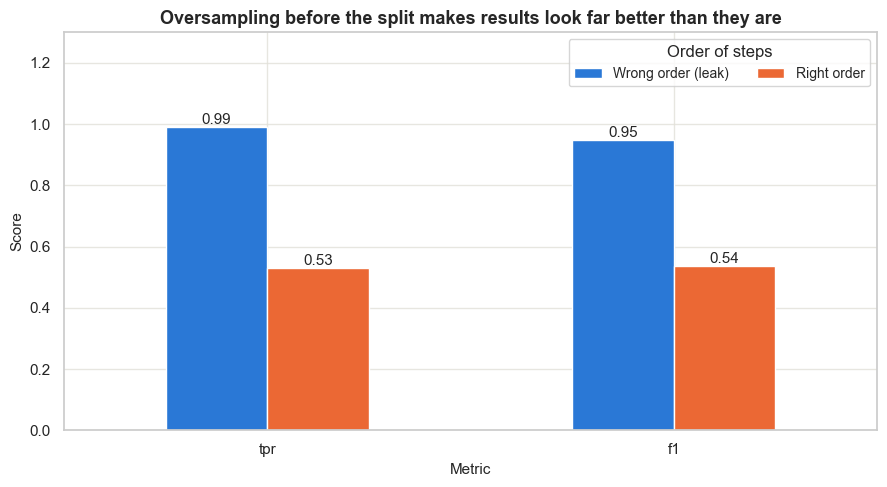

In [7]:
ax = demo.loc[["tpr", "f1"]].plot(kind="bar", color=COLOURS[:2], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")
ax.set_title("Oversampling before the split makes results look far better than they are")
ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.3)
ax.legend(title="Order of steps", loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

The wrong order looks far better than it really is. The tree seems to reach TPR 0.99 and F1 0.95, but with the right order it reaches only TPR 0.53 and F1 0.54. Accuracy also falls from 0.944 to 0.858. This is why the paper splits first, and why we do the same.

## 7. Key takeaways
We get 74 input columns, while the paper reports 70, and we could not explain the gap. The split gives 8,631 train rows and 3,699 test rows, both with about 15.5% buyers.

Oversampling lifts purchase rows in the train part from 1,336 to 7,295, and the test set stays the same (3,127 and 572). Doing it before the split would leak 97.2% of the test purchase rows into training. That would make a simple tree look like it reaches F1 0.95 when it really reaches 0.54.